## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

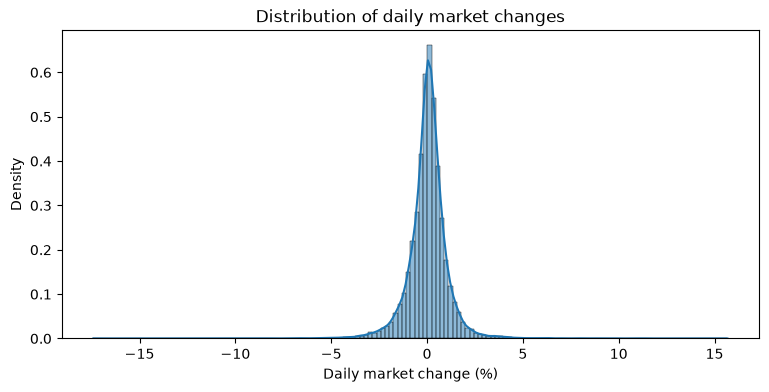

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

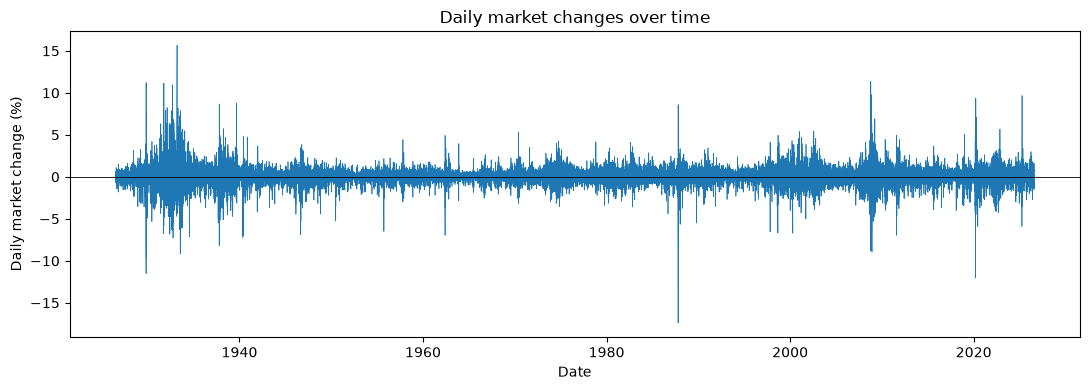

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [8]:
# Current and next trading day's market change (%)
df['r_t'] = df['market_return_pct']             
df['r_tp1'] = df['market_return_pct'].shift(-1)   

# Today's category: True if the market went up, False if down or flat
df['up_t'] = df['r_t'] > 0
df['y_t'] = df['up_t'].map({False: 'Down', True: 'Up'})

# Next day's category
df['y_tp1'] = df['y_t'].shift(-1)

df[['date', 'r_t', 'r_tp1', 'y_t', 'y_tp1']].tail()


,date,r_t,r_tp1,y_t,y_tp1
26291,2026-07-27,0.17,0.29,Up,Up
26292,2026-07-28,0.29,-1.50,Up,Down
26293,2026-07-29,-1.50,1.61,Down,Up
26294,2026-07-30,1.61,0.70,Up,Up
26295,2026-07-31,0.70,NaN,Up,NaN


In [9]:
# Counts each (today, next day) pair
pd.crosstab(df['y_t'], df['y_tp1'])


y_tp1,Down,Up
y_t,,
Down,5909,5999
Up,5999,8388


In [10]:
# Divides each count by the total number of complete pairs so the whole table sums to 1
joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
joint


y_tp1,Down,Up
y_t,,
Down,0.224720,0.228142
Up,0.228142,0.318996


In [11]:
# Divides each count by its row total so each row sums to 1
# Row i gives pr[next day = j | today = i]
conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditional


y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


Up transitions are more common than down transitions. The All row of the joint PMF with marginals shows that the next trading day is Up in 54.7% of the 26,295 complete day pairs and Down (and flat) in 45.3% of them. The raw counts give the same result with 14,387 pairs ending in an Up day (5,999 from Down plus 8,388 from Up) compared with 11,908 pairs ending in a Down (and flat) day (5,909 from Down plus 5,999 from Up).

A transition to an Up day is more likely from an Up day than from a Down (and flat) day. The conditional PMF shows that pr(Up next day | Up today) = 0.583, while pr(Up next day | Down today) = 0.504, so an Up day is followed by another Up day about 0.079 more often. This means today's category does carry some information about the next trading day's category.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [12]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

# Today's category
df['y_t'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)

# Next trading day's category
df['y_tp1'] = df['y_t'].shift(-1)

# Number of days in each bin
df['y_t'].value_counts()


y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [13]:
# Whole table sums to 1. All column = marginal of today, All row = marginal of next day
joint_5 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
joint_5


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


In [14]:
# row i gives pr[next day = j | today = i]
conditional_5 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditional_5


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


In [15]:
# Group by today's category and describe the next day's actual % change

df.groupby('y_t', observed=False)['r_tp1'].describe() # mean = conditional expectation, std = spread, min/max = extremes


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


Answer 2a:
Of the 26,296 trading days Small gain is the most common bin with 9,785 days, followed by Small loss with 7,452 days, Near zero with 3,441 days, and Large gain with 2,859 days, while Large loss is the least common bin with 2,759 days.

Answer 2b:
The most likely transition is from a Small gain day to another Small gain day with a joint probability of 0.159, followed by Small gain to Small loss (0.100), Small loss to Small gain (0.098), and Small loss to Small loss (0.089). The least likely transitions are Large loss to Near zero, Near zero to Large gain, and Near zero to Large loss, each with a joint probability of about 0.009. The All row of the joint PMF shows that the next trading day is most often a Small gain (0.372) and least often a Large loss (0.105).

Answer 2c:
For every current state, the two most likely next states are Small gain and Small loss. Small gain ranks first in every row of the conditional PMF ranging from 0.265 after a Large loss to 0.428 after a Small gain, and Small loss ranks second in every row ranging from 0.235 after a Large gain to 0.321 after a Near zero day.

Compared with a uniform PMF of 0.2 for each next state the Large loss row is the closest, with values between 0.086 and 0.265, while the Small gain row is the farthest, with values between 0.067 and 0.428. The Small loss, Near zero, and Large gain rows fall in between.

It is difficult to predict the next state. The highest probability in any row is 0.428 so even the most likely guess is wrong more often than it is right, and because Small gain is the most likely next state no matter what today's state is, knowing today's state does not change the best single guess.

Answer 2d:
Given the current state the expected next-day return is -0.038% after a Large loss, -0.044% after a Small loss, 0.015% after a Near zero day, 0.107% after a Small gain, and 0.163% after a Large gain. The expected return is negative after both loss states and positive after the other three, and it increases from Near zero to Large gain.

The minimum and maximum of the next day's return spread out the most after the two large states with Large loss days followed by returns between -17.41% and 11.22% and Large gain days followed by returns between -12.00% and 15.67%. In comparison Near zero days are followed by returns between -8.19% and 5.49%, and Small gain days by returns between -8.25% and 8.67%, while Small loss days fall in between at -11.23% to 11.36%.

Large loss has the highest standard deviation of next day returns at 1.721%, followed by Large gain at 1.384%, Small loss at 1.010%, Small gain at 0.832%, and Near zero at 0.826%. Larger moves in either direction are followed by a wider spread in the next day's return, which is the volatility clustering described in the course notes. Each loss state also has a higher standard deviation than the gain state of the same size (1.721% versus 1.384% for the large states and 1.010% versus 0.832% for the small states).

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [16]:
# Today's bin
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False)

# Next trading day's bin
df['y_tp1'] = df['y_t'].shift(-1).astype('Int64')


pd.qcut(df['market_return_pct'], q=21).value_counts(sort=False)


market_return_pct
(-17.411, -1.61]    1255
(-1.61, -1.07]      1253
(-1.07, -0.78]      1286
(-0.78, -0.57]      1280
(-0.57, -0.42]      1230
(-0.42, -0.3]       1226
(-0.3, -0.19]       1371
(-0.19, -0.11]      1206
(-0.11, -0.03]      1198
(-0.03, 0.04]       1331
(0.04, 0.11]        1210
(0.11, 0.18]        1223
(0.18, 0.26]        1294
(0.26, 0.34]        1223
(0.34, 0.44]        1310
(0.44, 0.54]        1193
(0.54, 0.67]        1211
(0.67, 0.84]        1283
(0.84, 1.09]        1225
(1.09, 1.55]        1250
(1.55, 15.67]       1238
Name: count, dtype: int64

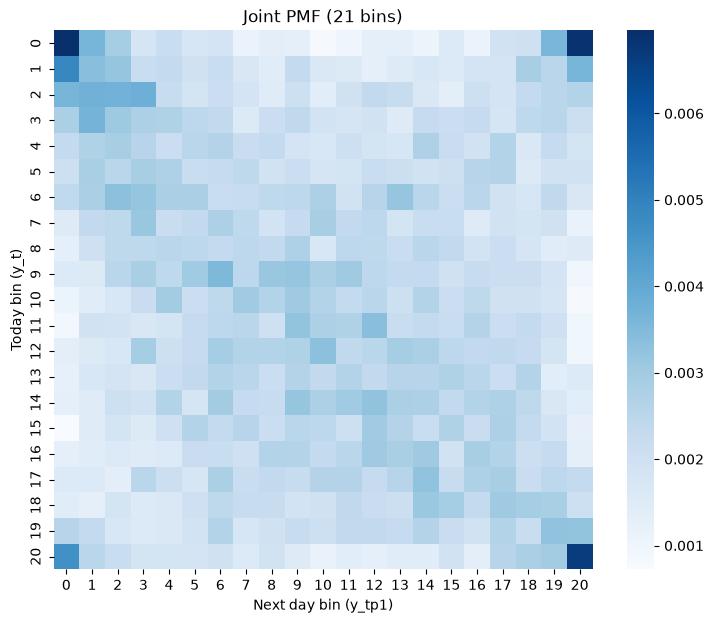

In [17]:
# Joint PMF
joint_21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)

# Heatmap of the joint PMF
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(joint_21, cmap='Blues', square=True, ax=ax)
ax.set(title='Joint PMF (21 bins)', xlabel='Next day bin (y_tp1)', ylabel='Today bin (y_t)')
plt.show()


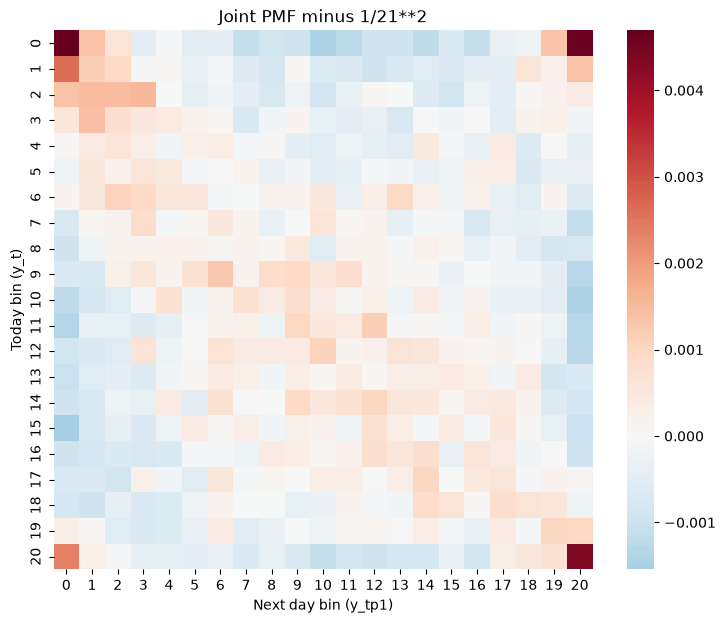

In [18]:
# Subtracts the uniform joint PMF
joint_21_dev = joint_21 - 1/21**2

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(joint_21_dev, cmap='RdBu_r', center=0, square=True, ax=ax)
ax.set(title='Joint PMF minus 1/21**2', xlabel='Next day bin (y_tp1)', ylabel='Today bin (y_t)')
plt.show()


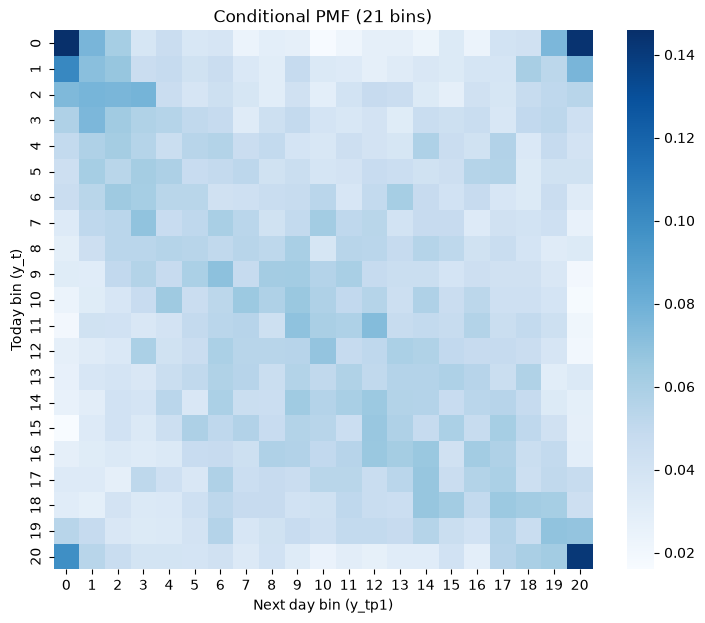

In [19]:
# Conditional PMF: row i gives pr[next bin = j | today bin = i]
conditional_21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(conditional_21, cmap='Blues', square=True, ax=ax)
ax.set(title='Conditional PMF (21 bins)', xlabel='Next day bin (y_tp1)', ylabel='Today bin (y_t)')
plt.show()


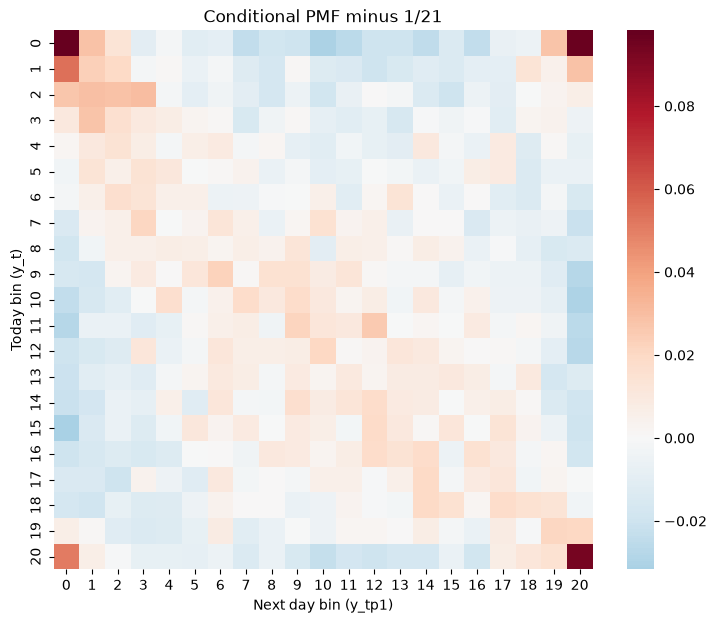

In [20]:
# Subtracts the uniform conditional PMF
conditional_21_dev = conditional_21 - 1/21

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(conditional_21_dev, cmap='RdBu_r', center=0, square=True, ax=ax)
ax.set(title='Conditional PMF minus 1/21', xlabel='Next day bin (y_tp1)', ylabel='Today bin (y_t)')
plt.show()


,min,mean,max
y_t,,,
0,-17.41,-0.013713,11.22
1,-7.36,-0.076712,6.36
2,-8.79,-0.097084,11.36
3,-8.28,-0.058594,6.16
4,-6.89,-0.024211,4.56
5,-11.23,-0.022692,6.37
6,-3.94,-0.030241,7.37
7,-3.40,-0.014303,4.76
8,-6.00,0.025860,5.49


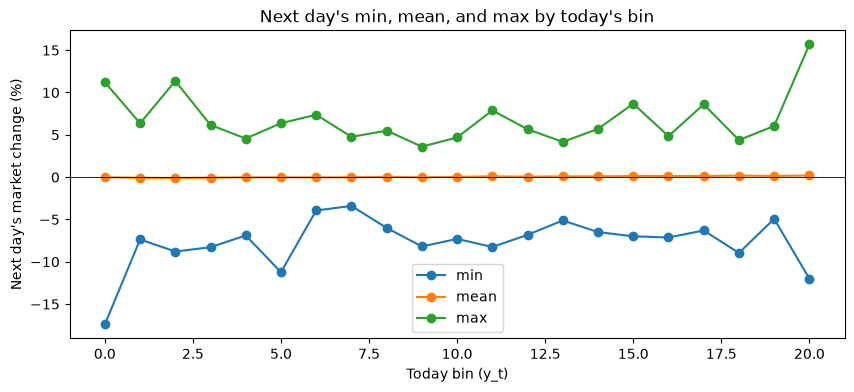

In [21]:
# Next day's min, mean, and max % change for each of today's bins 
next_stats = df.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max'])
display(next_stats)


fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(next_stats.index, next_stats['min'], marker='o', label='min')
ax.plot(next_stats.index, next_stats['mean'], marker='o', label='mean')
ax.plot(next_stats.index, next_stats['max'], marker='o', label='max')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Today bin (y_t)', ylabel="Next day's market change (%)",
       title="Next day's min, mean, and max by today's bin")
ax.legend()
plt.show()


y_t
0     2.140465
1     1.285882
2     1.227976
3     1.049607
4     0.989470
5     1.024761
6     0.930389
7     0.835663
8     0.853220
9     0.811559
10    0.805212
11    0.791857
12    0.784100
13    0.816509
14    0.831233
15    0.789961
16    0.826667
17    0.959673
18    0.900844
19    1.099897
20    1.702623
Name: r_tp1, dtype: float64

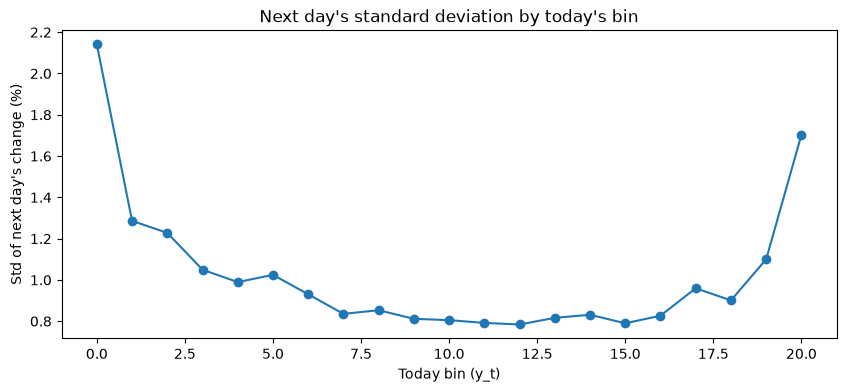

In [22]:
# Next day's standard deviation of % change for each of today's bins
next_std = df.groupby('y_t')['r_tp1'].std()
display(next_std)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(next_std.index, next_std, marker='o')
ax.set(xlabel='Today bin (y_t)', ylabel="Std of next day's change (%)",
       title="Next day's standard deviation by today's bin")
plt.show()


Answer 3b:
Yes, the joint PMF heatmap shows that the probability is concentrated in the four corners and in the middle of the table. The darkest cells are bin 0 followed by bin 0, bin 0 followed by bin 20, and bin 20 followed by bin 20, each above 0.006 on the colorbar, with bin 20 followed by bin 0 a lighter shade, compared with 0.00227 for a uniform joint PMF (1/212). Bin 0 holds returns at or below -1.61% and bin 20 holds returns above 1.55% so the largest moves in either direction are followed by other large moves more often than a uniform PMF would give. After subtracting 1/212 the four corners and the area where bins 0 to 3 are followed by bins 0 to 3 appear red, while columns 0 and 20 appear blue for the middle rows, which means that days in the middle bins are followed by an extreme day less often than uniform and by another middle bin more often than uniform.

Answer 3c:
Yes, the conditional PMF heatmap shows the same pattern. After a bin 0 day the most likely next bins are bin 0 and bin 20 each with a conditional probability of about 0.14, and after a bin 20 day the most likely next bin is bin 20 at about 0.14, followed by bin 0 at about 0.10, compared with 0.048 for a uniform conditional PMF (1/21). After subtracting 1/21, the middle rows stay within about 0.03 of uniform, while the corners reach about 0.09 above uniform so the departures from uniformly random transitions are concentrated in the rows for the most extreme bins.

Answer 3d:
Yes, the mean line stays close to 0 for every bin ranging from -0.097% after bin 2 to 0.195% after bin 20 with negative means for bins 0 to 7 and bin 9 and positive means for bin 8 and bins 10 to 20. The min and max lines spread out at the two ends with bin 0 days followed by returns between -17.41% and 11.22% and bin 20 days followed by returns between -12.00% and 15.67%, while middle bins have narrower ranges such as -3.40% to 4.76% after bin 7. The lines are uneven in between with bin 2 reaching a max of 11.36% and bin 5 reaching a min of -11.23% but overall the next day's extreme values change more across bins than the next day's mean does.

Answer 3e:
Yes, the standard deviation forms a U shape across the bins. It is highest after bin 0 at 2.140% and after bin 20 at 1.703%, and it stays between 0.784% and 0.853% for bins 7 through 16, with the lowest value after bin 12 at 0.784%. The loss side is higher than the gain side at the same distance from the middle bin, for example 1.286% after bin 1 compared with 1.100% after bin 19, and 1.228% after bin 2 compared with 0.901% after bin 18 which matches the loss and gain comparison from Part 2.

Answer 3f:
No, it is not easy to predict the market. Even in the most predictable rows the most likely next bin has a conditional probability of only about 0.14, the middle rows stay within about 0.03 of the uniform value of 0.048, and the expected next day return ranges only from -0.097% to 0.195% while the standard deviations range from 0.784% to 2.140%. Today's bin does help predict how large the next day's move might be since the standard deviation after bin 0 is 2.140% compared with 0.784% after bin 12 but it gives little help in predicting the direction since a bin 0 day is followed by bin 0 and by bin 20 with about the same probability.